# D-8: Propensity-score matching for repairs, and KMeans customer segments
**Part A.** Do repair users stop shopping less than *truly comparable* non-users? Each repair user is paired with
the non-user who was **equally likely to start using repairs**, based on many features at once
(`LogisticRegression` → propensity score, `NearestNeighbors` → closest match).

**Part B.** What kinds of customers does Lululime have today? `KMeans` on recency, frequency, spend and behaviour,
then a profile and the share of ARR each segment holds.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from src import config as C
from src.metrics import load

OUT = ROOT / "results" / "d_customers_arr"
BLUE, ORANGE, GREY, LIGHT = "#2a78d6", "#eb6834", "#8a8a85", "#b7d3f6"
INK, INK2, GRID = "#0b0b0b", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 12,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "text.parse_math": False,
})
SEED = 42

lines = load()
visits = load("visits")
customers = load("customers").set_index("customer_id")

## Part A. Propensity-score matching
**Fair timing (same landmark design as the external review, `docs/review/review_checks.py` §5):**
- Cohort: customers who shopped in the year before repairs launched (Apr 2024 – Mar 2025) **and** made a purchase
  between Apr and Sep 2025, so everyone was still an active customer during the same window.
- **Repair user** = first repair by 30 Sep 2025. **Non-user** = no repair by then.
- **Outcome:** no purchase in the last 180 days as of 31 Oct 2026 (purchase visits only, so pickup trips don't count).
- **Matching features, all measured by 30 Sep 2025:** age band, area, channel, interests, years since signup,
  loyalty member and Silver/Gold, spend, purchase visits and returns in the pre-launch year, spend on outerwear
  (people who own jackets have more to repair), and purchase visits and spend in Apr–Sep 2025.

In [2]:
L1 = pd.Timestamp("2025-09-30")
PRE_S, PRE_E = C.REPAIRS_LAUNCH - pd.DateOffset(years=1), C.REPAIRS_LAUNCH - pd.Timedelta(days=1)
pre_v = visits[visits["date"].between(PRE_S, PRE_E)]
win_v = visits[visits["date"].between(C.REPAIRS_LAUNCH, L1) & visits["has_purchase"]]
cohort = customers.loc[customers.index.intersection(pre_v["customer_id"].unique())
                       .intersection(win_v["customer_id"].unique())].copy()

cohort["treated"] = (cohort["first_repair_date"] <= L1).astype(int)
gp, gw = pre_v.groupby("customer_id"), win_v.groupby("customer_id")
cohort["pre_spend"] = gp["revenue"].sum()
cohort["pre_purchase_visits"] = gp["has_purchase"].sum()
cohort["pre_returns"] = gp["has_return"].sum()
pre_lines = lines[lines["date"].between(PRE_S, PRE_E) & (lines["row_type"] == C.PURCHASE)]
cohort["pre_outerwear_spend"] = pre_lines[pre_lines["category"] == "Outerwear"].groupby("customer_id")["revenue"].sum()
cohort["win_purchase_visits"] = gw.size()
cohort["win_spend"] = gw["revenue"].sum()
cohort["tenure_years"] = (L1 - cohort["signup_date"]).dt.days / 365
cohort["member"] = (cohort["loyalty_join_date"] <= L1).fillna(False).astype(int)
tier = visits[visits["date"] <= L1].sort_values("datetime").groupby("customer_id")["tier"].last()
cohort["silver_gold"] = tier.reindex(cohort.index).isin(["Silver", "Gold"]).astype(int)
last_purchase = visits[visits["has_purchase"]].groupby("customer_id")["date"].max()
cohort["churned"] = ((C.AS_OF_DATE - cohort.index.map(last_purchase)).days > C.CHURN_DAYS).astype(int)
cohort = cohort.fillna({"pre_outerwear_spend": 0})

NUM = ["pre_spend", "pre_purchase_visits", "pre_returns", "pre_outerwear_spend", "win_purchase_visits",
       "win_spend", "tenure_years"]
BIN = ["member", "silver_gold", "interest_run", "interest_yoga", "interest_pilates", "interest_outdoor",
       "interest_lifestyle"]
CAT = ["age_band", "home_area", "acquisition_channel"]
Xp = pd.concat([cohort[NUM].apply(lambda s: np.log1p(s.clip(lower=0))), cohort[BIN].astype(float),
                pd.get_dummies(cohort[CAT], drop_first=True, dtype=float)], axis=1)
Xs = StandardScaler().fit_transform(Xp)

ps_model = LogisticRegression(max_iter=3000, C=1.0).fit(Xs, cohort["treated"])
cohort["pscore"] = ps_model.predict_proba(Xs)[:, 1]
cohort["logit_ps"] = np.log(cohort["pscore"] / (1 - cohort["pscore"]))
print(f"Cohort {len(cohort):,} customers: {cohort['treated'].sum():,} repair users, "
      f"{(1 - cohort['treated']).sum():,} non-users")

Cohort 3,478 customers: 833 repair users, 2,645 non-users


**Matching:** each repair user gets the non-user with the closest propensity score (1-to-1, with replacement),
but only if the two are within 0.2 standard deviations of each other (a standard "caliper"). Users with no close
match are dropped and reported.

In [3]:
def match(df, caliper_sd=0.2):
    t, c = df[df["treated"] == 1], df[df["treated"] == 0]
    nn = NearestNeighbors(n_neighbors=1).fit(c[["logit_ps"]])
    dist, idx = nn.kneighbors(t[["logit_ps"]])
    ok = dist[:, 0] <= caliper_sd * df["logit_ps"].std()
    return t[ok], c.iloc[idx[ok, 0]]


treat_m, ctrl_m = match(cohort)
att = treat_m["churned"].mean() - ctrl_m["churned"].mean()

rng = np.random.default_rng(SEED)
boot = []
for _ in range(300):
    b = cohort.iloc[rng.integers(0, len(cohort), len(cohort))]
    tb, cb = match(b)
    boot.append(tb["churned"].mean() - cb["churned"].mean())
lo, hi = np.percentile(boot, [2.5, 97.5])

raw = cohort.groupby("treated")["churned"].mean()
psm = pd.Series({
    "repair users in cohort": int(cohort["treated"].sum()),
    "repair users matched": len(treat_m),
    "distinct non-users used as matches": ctrl_m.index.nunique(),
    "churn, repair users (%)": raw[1] * 100,
    "churn, all non-users (%)": raw[0] * 100,
    "raw gap (pts)": (raw[1] - raw[0]) * 100,
    "churn, matched repair users (%)": treat_m["churned"].mean() * 100,
    "churn, their matched non-users (%)": ctrl_m["churned"].mean() * 100,
    "matched gap (pts)": att * 100,
    "matched gap, 95% low (pts)": lo * 100,
    "matched gap, 95% high (pts)": hi * 100,
}).round(1)
psm

repair users in cohort                833.0
repair users matched                  828.0
distinct non-users used as matches    489.0
churn, repair users (%)                17.0
churn, all non-users (%)               50.8
raw gap (pts)                         -33.8
churn, matched repair users (%)        17.0
churn, their matched non-users (%)     30.2
matched gap (pts)                     -13.2
matched gap, 95% low (pts)            -18.1
matched gap, 95% high (pts)            -7.6
dtype: float64

**Balance check.** Matching only works if matched users and non-users now look alike. Standardised mean
difference (SMD) = gap in a feature's average ÷ its spread. Under 0.1 is the usual "balanced" threshold.

In [4]:
def smd(a, b):
    s = np.sqrt((a.var() + b.var()) / 2)
    return (a.mean() - b.mean()) / s if s > 0 else 0.0


SHOW = {"pre_spend": "Spend, year before launch", "pre_purchase_visits": "Purchase visits, year before",
        "pre_outerwear_spend": "Outerwear spend, year before", "win_purchase_visits": "Purchase visits, Apr–Sep 2025",
        "win_spend": "Spend, Apr–Sep 2025", "tenure_years": "Years as a customer", "member": "Loyalty member",
        "silver_gold": "Silver or Gold tier", "pre_returns": "Returns, year before", "interest_outdoor": "Outdoor interest"}
t_all, c_all = cohort[cohort["treated"] == 1], cohort[cohort["treated"] == 0]
balance = pd.DataFrame({
    "before matching": {lab: smd(t_all[k], c_all[k]) for k, lab in SHOW.items()},
    "after matching": {lab: smd(treat_m[k], ctrl_m[k]) for k, lab in SHOW.items()},
}).round(2)
balance

,before matching,after matching
"Spend, year before launch",0.83,0.02
"Purchase visits, year before",0.79,-0.01
"Outerwear spend, year before",0.69,-0.02
"Purchase visits, Apr–Sep 2025",1.13,0.06
"Spend, Apr–Sep 2025",1.09,0.10
Years as a customer,0.37,-0.10
Loyalty member,0.53,-0.08
Silver or Gold tier,0.86,-0.02
"Returns, year before",0.58,-0.00
Outdoor interest,0.13,0.02


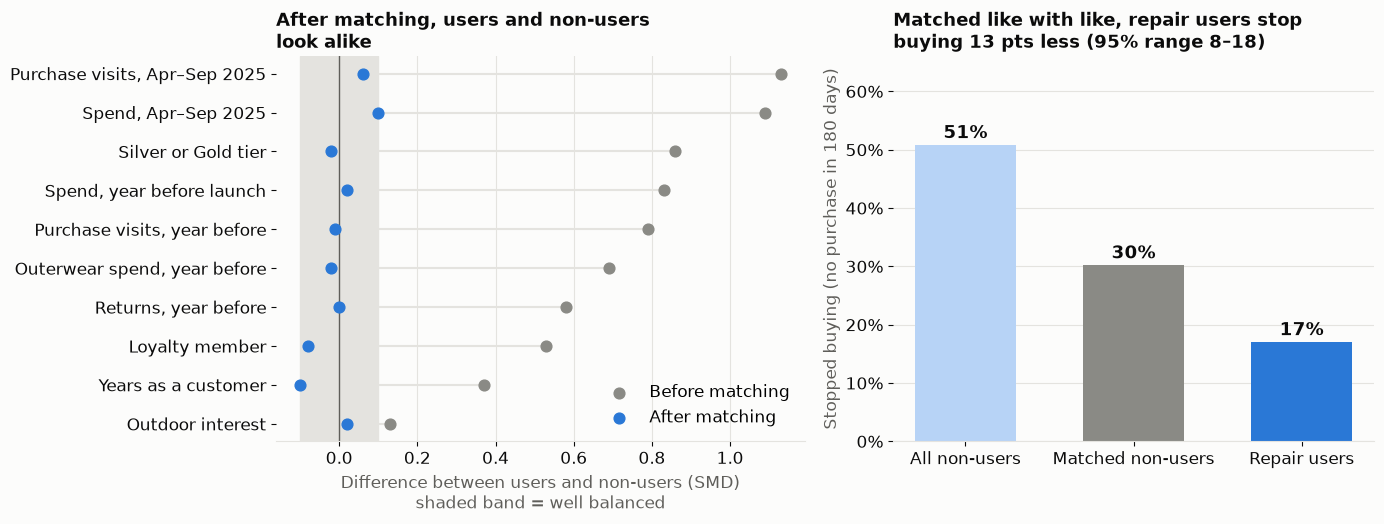

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
order = balance["before matching"].abs().sort_values().index
y = np.arange(len(order))
a1.axvspan(-0.1, 0.1, color=GRID, zorder=0)
a1.scatter(balance.loc[order, "before matching"], y, color=GREY, s=60, label="Before matching", zorder=3)
a1.scatter(balance.loc[order, "after matching"], y, color=BLUE, s=60, label="After matching", zorder=3)
for i, k in enumerate(order):
    a1.plot([balance.loc[k, "before matching"], balance.loc[k, "after matching"]], [i, i], color=GRID, lw=1.5, zorder=2)
a1.set_yticks(y, order)
a1.axvline(0, color=INK2, lw=1)
a1.set_xlabel("Difference between users and non-users (SMD)\nshaded band = well balanced")
a1.set_title("After matching, users and non-users\nlook alike", loc="left", color=INK, fontsize=13, fontweight="bold")
a1.legend(loc="lower right", frameon=False)
a1.grid(axis="y", visible=False)

labs = ["All non-users", "Matched non-users", "Repair users"]
vals = [raw[0] * 100, ctrl_m["churned"].mean() * 100, treat_m["churned"].mean() * 100]
bars = a2.bar(labs, vals, color=[LIGHT, GREY, BLUE], width=0.6)
for b, v in zip(bars, vals):
    a2.annotate(f"{v:.0f}%", (b.get_x() + b.get_width() / 2, v), xytext=(0, 5), textcoords="offset points",
                ha="center", color=INK, fontsize=13, fontweight="bold")
a2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a2.set_ylim(0, max(vals) * 1.3)
a2.set_ylabel("Stopped buying (no purchase in 180 days)")
a2.set_title(f"Matched like with like, repair users stop\nbuying {abs(att) * 100:.0f} pts less "
             f"(95% range {abs(hi) * 100:.0f}–{abs(lo) * 100:.0f})", loc="left", color=INK, fontsize=13, fontweight="bold")
a2.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT / "d8_propensity_matching.png", dpi=200)
plt.show()

## Part B. KMeans customer segments
**Who:** every customer who made a purchase in the last 12 months (as of 31 Oct 2026).
**Clustered on behaviour only:** days since last purchase, purchase visits, spend, average basket, share of
spend paid with points, return rate, years as a customer, repair use, age. (Skewed ones log-scaled, all
standardised.) Interests, tier and channel are left out of the clustering and used afterwards to *describe*
the segments. Yes/no interest columns otherwise dominate the distances.
**Choosing k:** silhouette score for k = 3–7 (higher = clearer separation). k = 3 separates slightly better,
but k = 4 also splits out frequent returners, which matters for the points recommendation, so we use 4.

In [6]:
END = C.DATA_END
y12 = visits[visits["date"] > END - pd.Timedelta(days=365)]
buyers = y12.loc[y12["has_purchase"], "customer_id"].unique()
g = y12[y12["customer_id"].isin(buyers)].groupby("customer_id")
seg = customers.loc[buyers].copy()
seg["purchase_visits"] = g["has_purchase"].sum()
seg["spend"] = g["revenue"].sum().clip(lower=0)
seg["avg_basket"] = seg["spend"] / seg["purchase_visits"]
seg["points_share"] = (g["redeemed_dollars"].sum() / g["revenue"].sum().where(lambda s: s > 0)).fillna(0).clip(0, 1)
seg["return_rate"] = g["has_return"].sum() / g.size()
seg["days_since_purchase"] = (END - visits[visits["has_purchase"]].groupby("customer_id")["date"].max()
                              .reindex(seg.index)).dt.days
seg["tenure_years"] = (END - seg["signup_date"]).dt.days / 365
seg["repair_user"] = seg["used_repair"].fillna(False).astype(int)
seg["age_num"] = seg["age_band"].map({"18-24": 21, "25-34": 30, "35-44": 40, "45-54": 50, "55+": 60})
seg["age_num"] = seg["age_num"].fillna(seg["age_num"].median())

FEATS = ["days_since_purchase", "purchase_visits", "spend", "avg_basket", "points_share", "return_rate",
         "tenure_years", "repair_user", "age_num"]
Z = seg[FEATS].astype(float).copy()
for c in ["days_since_purchase", "purchase_visits", "spend", "avg_basket"]:
    Z[c] = np.log1p(Z[c])
Zs = StandardScaler().fit_transform(Z)
sil = {k: silhouette_score(Zs, KMeans(k, n_init=10, random_state=SEED).fit_predict(Zs), sample_size=4000,
                           random_state=SEED) for k in range(3, 8)}
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()})

seg["segment"] = KMeans(4, n_init=20, random_state=SEED).fit_predict(Zs)
profile = seg.groupby("segment").agg(
    customers=("spend", "size"), arr=("arr_12m", "sum"),
    visits_per_year=("purchase_visits", "mean"), spend_per_year=("spend", "mean"), avg_basket=("avg_basket", "mean"),
    days_since_purchase=("days_since_purchase", "median"), repair_users=("repair_user", "mean"),
    gold=("max_tier", lambda s: (s == "Gold").mean()), age_18_24=("age_band", lambda s: (s == "18-24").mean()),
    avg_age=("age_num", "mean"), return_rate=("return_rate", "mean"), points_share=("points_share", "mean"),
    years_customer=("tenure_years", "mean"), outdoor=("interest_outdoor", "mean"), pilates=("interest_pilates", "mean"),
)
profile["share of customers (%)"] = profile["customers"] / profile["customers"].sum() * 100
profile["share of ARR (%)"] = profile["arr"] / profile["arr"].sum() * 100

# Name segments from their profile (rules, so the names survive a re-run)
names, left = {}, set(profile.index)
top = profile["arr"].idxmax(); names[top] = "Gold regulars"; left.discard(top)
ret = profile.loc[list(left), "return_rate"].idxmax(); names[ret] = "Frequent returners"; left.discard(ret)
young = profile.loc[list(left), "age_18_24"].idxmax(); names[young] = "Fading young, light shoppers"; left.discard(young)
names[left.pop()] = "Occasional big-basket shoppers"
profile.index = profile.index.map(names)
seg["segment_name"] = seg["segment"].map(names)
ORDER = ["Gold regulars", "Occasional big-basket shoppers", "Fading young, light shoppers", "Frequent returners"]
profile = profile.loc[ORDER]
profile.round(2)

Silhouette by k: {3: 0.285, 4: 0.189, 5: 0.174, 6: 0.191, 7: 0.193}


,customers,arr,visits_per_year,spend_per_year,avg_basket,days_since_purchase,repair_users,gold,age_18_24,avg_age,return_rate,points_share,years_customer,outdoor,pilates,share of customers (%),share of ARR (%)
segment,,,,,,,,,,,,,,,,,
Gold regulars,1930,5317946.4,18.08,2773.82,153.43,16.0,0.89,0.75,0.13,36.25,0.09,0.07,3.54,0.29,0.09,31.77,79.68
Occasional big-basket shoppers,1913,968765.7,3.46,606.59,199.42,70.0,0.10,0.05,0.03,40.77,0.02,0.02,1.49,0.28,0.10,31.49,14.52
"Fading young, light shoppers",1605,211250.4,1.91,179.56,96.77,144.0,0.06,0.01,0.30,29.77,0.00,0.01,1.60,0.23,0.11,26.42,3.17
Frequent returners,627,175926.6,2.83,350.81,124.07,125.0,0.14,0.04,0.16,35.98,0.33,0.03,1.87,0.23,0.11,10.32,2.64


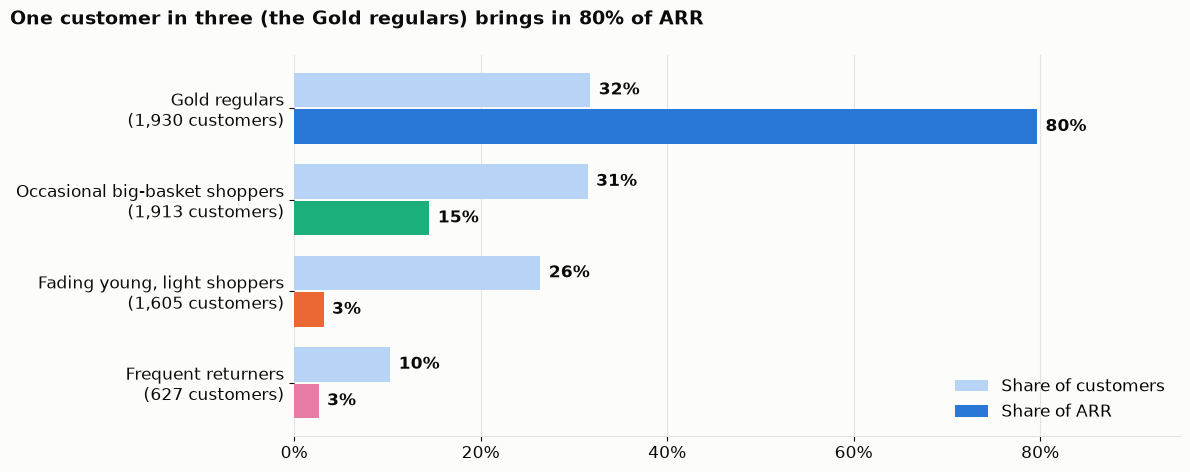

In [7]:
COLORS = {"Gold regulars": BLUE, "Occasional big-basket shoppers": "#1baf7a",
          "Fading young, light shoppers": ORANGE, "Frequent returners": "#e87ba4"}
fig, ax = plt.subplots(figsize=(12, 4.8))
y = np.arange(len(ORDER))
b1 = ax.barh(y - 0.2, profile["share of customers (%)"], 0.38, color=LIGHT, label="Share of customers")
b2 = ax.barh(y + 0.2, profile["share of ARR (%)"], 0.38, color=[COLORS[o] for o in ORDER], label="Share of ARR")
for bars in (b1, b2):
    for b in bars:
        ax.annotate(f"{b.get_width():.0f}%", (b.get_width(), b.get_y() + b.get_height() / 2), xytext=(6, 0),
                    textcoords="offset points", va="center", color=INK, fontsize=12, fontweight="bold")
ax.set_yticks(y, [f"{o}\n({int(profile.loc[o, 'customers']):,} customers)" for o in ORDER])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 95)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
fig.suptitle("One customer in three (the Gold regulars) brings in 80% of ARR", x=0.01, ha="left",
             color=INK, fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT / "d8_segments_arr.png", dpi=200)
plt.show()

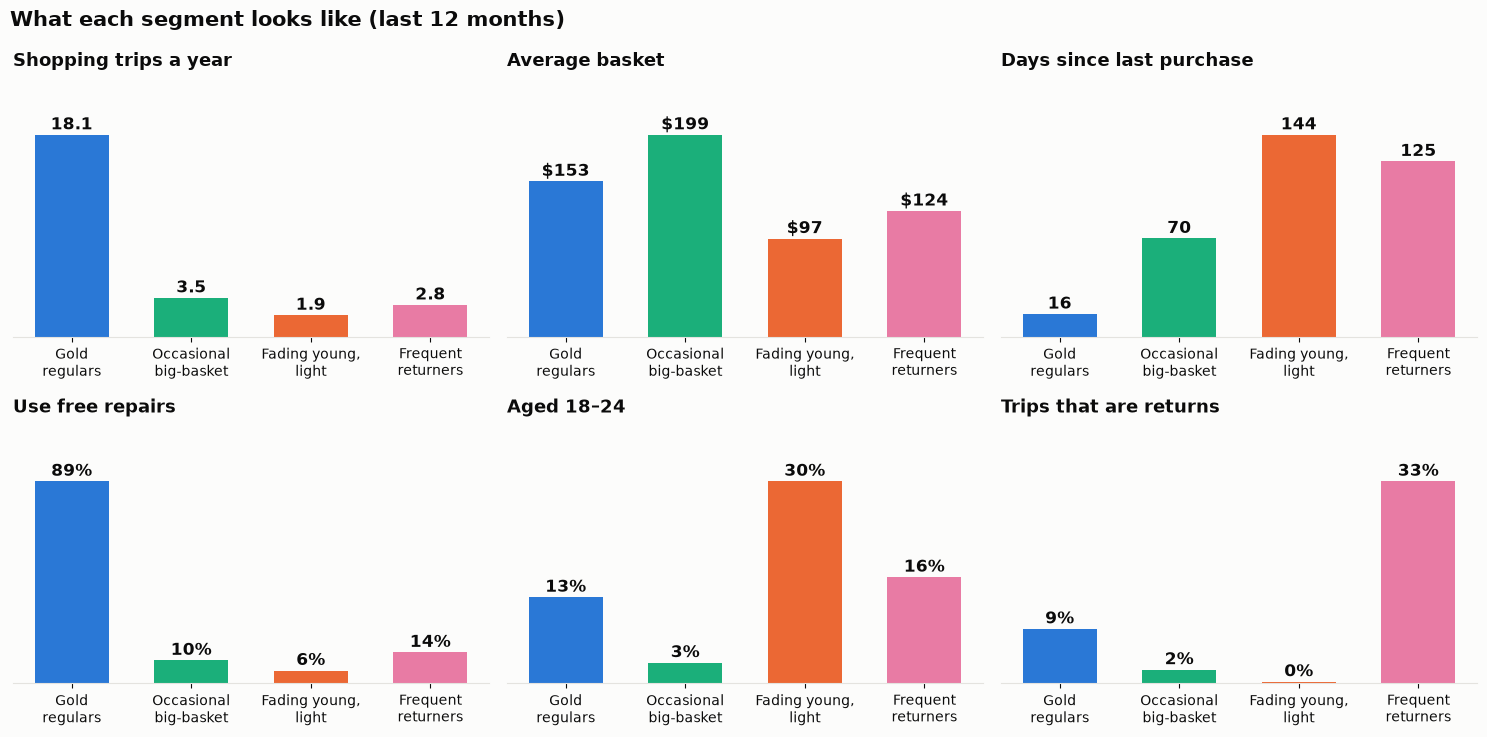

In [8]:
METRICS = [("visits_per_year", "Shopping trips a year", lambda v: f"{v:.1f}"),
           ("avg_basket", "Average basket", lambda v: f"${v:,.0f}"),
           ("days_since_purchase", "Days since last purchase", lambda v: f"{v:.0f}"),
           ("repair_users", "Use free repairs", lambda v: f"{v:.0%}"),
           ("age_18_24", "Aged 18–24", lambda v: f"{v:.0%}"),
           ("return_rate", "Trips that are returns", lambda v: f"{v:.0%}")]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
short = ["Gold\nregulars", "Occasional\nbig-basket", "Fading young,\nlight", "Frequent\nreturners"]
for ax, (col, title, fmt) in zip(axes.flat, METRICS):
    vals = profile.loc[ORDER, col]
    bars = ax.bar(short, vals, color=[COLORS[o] for o in ORDER], width=0.62)
    for b, v in zip(bars, vals):
        ax.annotate(fmt(v), (b.get_x() + b.get_width() / 2, v), xytext=(0, 4), textcoords="offset points",
                    ha="center", color=INK, fontsize=12, fontweight="bold")
    ax.set_ylim(0, vals.max() * 1.3)
    ax.set_yticks([])
    ax.set_title(title, loc="left", color=INK, fontsize=13, fontweight="bold")
    ax.grid(False)
    ax.tick_params(axis="x", labelsize=10)
fig.suptitle("What each segment looks like (last 12 months)", x=0.01, ha="left", color=INK, fontsize=15,
             fontweight="bold")
fig.tight_layout()
fig.savefig(OUT / "d8_segment_profiles.png", dpi=200)
plt.show()

## Caveats
- **Matching** balances only what we measured. Customers who chose repairs may still differ in ways the data
  can't see (e.g. how attached they are to their gear), so −13 pts is "after accounting for everything observable".
  It's consistent with the external review's landmark estimate (~16 pts) and D's churn model (5–9 pts on a
  6-month horizon).
- **Segments** describe customers; they don't say why. Silhouette scores are modest (~0.2), as is usual for
  customer data: the edges between segments are blurry, the cores are distinct.